# Section 2.7: Advanced $\epsilon$-$\delta$ Proofs — The Safety Net & Bounding Amplifiers

## Proving $\lim_{x \to 2} 3x^2 = 12$ From First Principles

When a function has non-linear terms like $x^2$, the difference between the function and its limit does not factor cleanly into just a constant times $|x - a|$. Instead, you get an extra variable factor — an **"amplifier"** — that can blow up if we are not careful.

Here we show how to install a **preliminary safety net** on $\delta$ to tame the amplifier, why lower and upper bounds work intuitively, and how to visualize the whole process.

---

## 1. Goal and Setup

**Goal:** Prove using the formal $\epsilon$-$\delta$ definition that

$$\lim_{x \to 2} 3x^2 = 12.$$

Given any $\epsilon > 0$, we must find a $\delta > 0$ such that:

$$\text{If } 0 < |x - 2| < \delta, \quad\text{then } |3x^2 - 12| < \epsilon.$$

---

## 2. Breaking Down the Error Term

Factor the error expression:

$$|3x^2 - 12| = |3(x^2 - 4)| = 3|x^2 - 4|.$$

Notice that $x^2 - 4$ is a difference of squares: $(x - 2)(x + 2)$. Therefore:

$$|3x^2 - 12| = 3 \cdot |x - 2| \cdot |x + 2|.$$

Look closely at the two pieces:
1. **$|x - 2|$** is our target control knob. We can make this as small as we want using $\delta$.
2. **$|x + 2|$** is the **amplifier** (multiplier). It depends on $x$! Since our final $\delta$ cannot depend on $x$, we cannot simply divide by $|x + 2|$.

---

## 3. The Intuition: Safety Net & Worst-Case Amplifier

### Why do we need a safety net?
Before we decide how tiny $\delta$ needs to be, we first promise that $\delta$ won't be wild. We install a provisional safety net: **let $\delta \le 1$**.

### Where does $x$ live inside the safety net?
$$
|x - 2| < 1 \iff -1 < x - 2 < 1 \iff 1 < x < 3.
$$

* $x$ is strictly between $1$ and $3$.
* $x$ can never reach $3$ (it might be $2.999$, but never $3$ or higher).

### What is the worst-case behavior of the amplifier $|x + 2|$?
Add $2$ across the inequality $1 < x < 3$:

$$
1 + 2 < x + 2 < 3 + 2 \implies 3 < x + 2 < 5.
$$

| Boundary | Value of $x$ | Amplifier $x + 2$ | Meaning |
|---|---|---|---|
| **Lower Bound** | $x \to 1^+$ | $x + 2 \to 3$ | The *quietest* the amplifier gets inside the safety window. |
| **Center (Target)** | $x = 2$ | $x + 2 = 4$ | The nominal multiplier at the limit point. |
| **Upper Bound (Worst Case)** | $x \to 3^-$ | $x + 2 \to 5$ | The *loudest* the amplifier can ever get inside the safety window. |

> **Why Upper Bound instead of Lower Bound?**
> We need to guarantee that the *entire* error stays strictly below $\epsilon$ under **any** circumstance.
> If we protect ourselves against the worst-case maximum ($5$), then everywhere else in the window where $x+2 < 5$ (e.g. $4$ or $3.5$), our error will be even smaller!

---

## 4. Solving for $\delta$

Under the safety net $|x - 2| < 1$, we know $|x + 2| < 5$. Therefore:

$$|3x^2 - 12| = 3|x - 2||x + 2| < 3 \cdot 5 \cdot |x - 2| = 15|x - 2|.$$

To make sure this error is strictly less than $\epsilon$, we set:

$$15|x - 2| < \epsilon \implies |x - 2| < \frac{\epsilon}{15}.$$

To satisfy both requirements (the safety net $\delta \le 1$ and the error bound $|x - 2| < \epsilon / 15$):

$$\delta = \min\left(1,\, \frac{\epsilon}{15}\right).$$

---

## 5. The Formal Proof

**Proof.**
Let $\epsilon > 0$ be given. Choose $\delta = \min\left(1,\, \dfrac{\epsilon}{15}\right)$.

Assume $0 < |x - 2| < \delta$.

1. Since $\delta \le 1$, we have $|x - 2| < 1$, which means $-1 < x - 2 < 1$, so $1 < x < 3$. Adding $2$ gives $3 < x + 2 < 5$, and therefore $|x + 2| < 5$.

2. Since $\delta \le \dfrac{\epsilon}{15}$, we have $|x - 2| < \dfrac{\epsilon}{15}$.

Combining these two inequalities:

$$
|3x^2 - 12| = 3|x - 2||x + 2| < 3 \cdot \left(\frac{\epsilon}{15}\right) \cdot 5 = \epsilon.
$$

Hence, $|3x^2 - 12| < \epsilon$, which completes the proof. $\blacksquare$

In [1]:
# Setup visualization environment
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = [11, 7]
plt.rcParams['font.size'] = 12

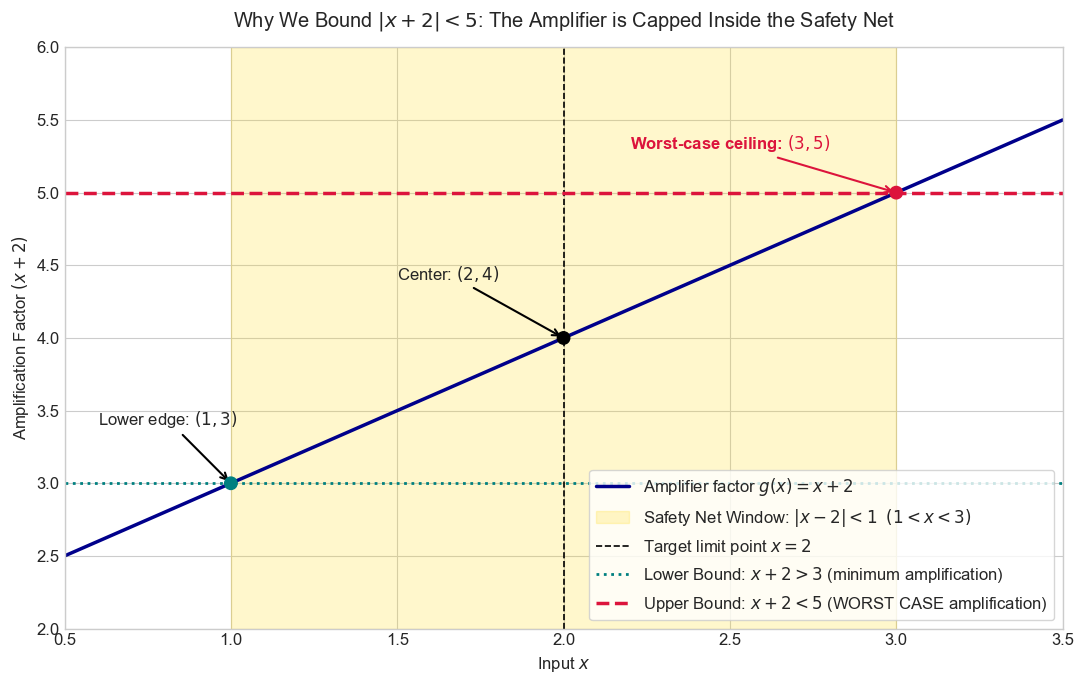

In [2]:
# Visualizing the Safety Net & the Amplifier |x + 2|

x_vals = np.linspace(0.5, 3.5, 400)
amplifier = x_vals + 2

fig, ax = plt.subplots()

# Plot the amplifier function |x + 2|
ax.plot(x_vals, amplifier, color='darkblue', lw=2.5, label=r'Amplifier factor $g(x) = x + 2$')

# Safety net window: 1 < x < 3 (where |x - 2| < 1)
ax.axvspan(1, 3, color='gold', alpha=0.2, label=r'Safety Net Window: $|x - 2| < 1$  $(1 < x < 3)$')
ax.axvline(2, color='black', ls='--', lw=1.2, label=r'Target limit point $x = 2$')

# Lower and Upper bounds inside the window
ax.axhline(3, color='teal', ls=':', lw=2, label=r'Lower Bound: $x + 2 > 3$ (minimum amplification)')
ax.axhline(5, color='crimson', ls='--', lw=2.5, label=r'Upper Bound: $x + 2 < 5$ (WORST CASE amplification)')

# Highlight the critical values
ax.scatter([1, 2, 3], [3, 4, 5], color=['teal', 'black', 'crimson'], s=80, zorder=5)
ax.annotate(r'Lower edge: $(1, 3)$', xy=(1, 3), xytext=(0.6, 3.4), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'Center: $(2, 4)$', xy=(2, 4), xytext=(1.5, 4.4), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'Worst-case ceiling: $(3, 5)$', xy=(3, 5), xytext=(2.2, 5.3), arrowprops=dict(arrowstyle='->', lw=1.5, color='crimson'), color='crimson', fontweight='bold')

ax.set_title('Why We Bound $|x+2| < 5$: The Amplifier is Capped Inside the Safety Net', pad=15)
ax.set_xlabel('Input $x$')
ax.set_ylabel('Amplification Factor $(x + 2)$')
ax.set_xlim(0.5, 3.5)
ax.set_ylim(2, 6)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

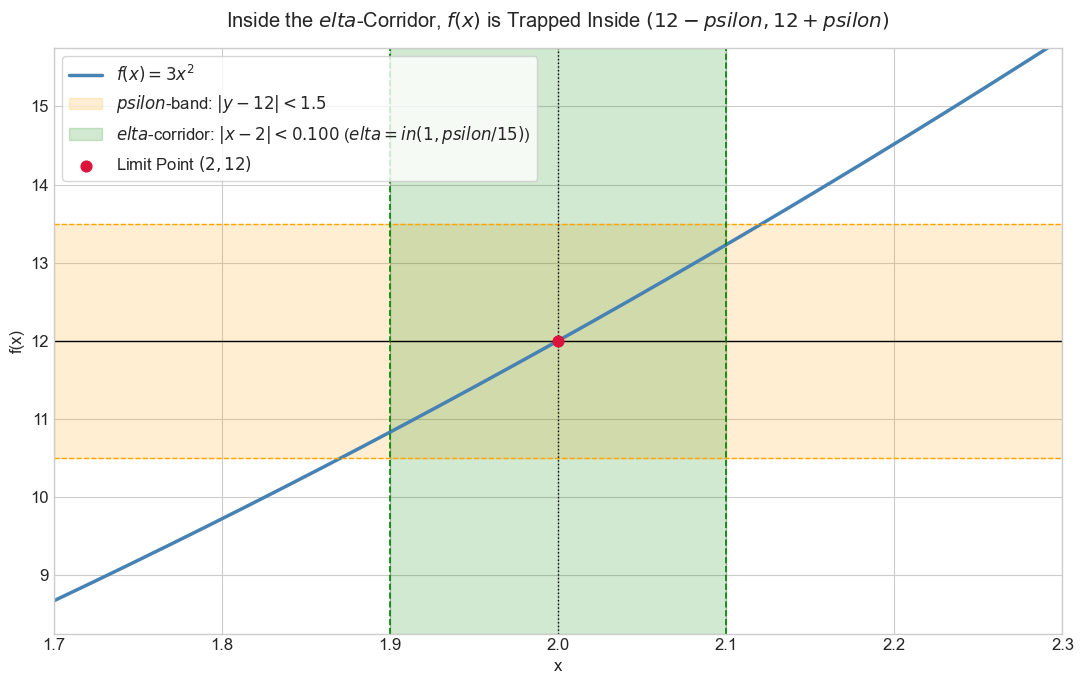

In [3]:
# Visualizing the Function 3x^2 inside the Epsilon-Delta Band

def f(x):
    return 3 * x**2

L = 12.0
c = 2.0
eps = 1.5
delta = min(1.0, eps / 15.0)  # delta = 1.5 / 15 = 0.1

x = np.linspace(1.7, 2.3, 500)
y = f(x)

fig, ax = plt.subplots()
ax.plot(x, y, color='steelblue', lw=2.5, label=r'$f(x) = 3x^2$')

# Horizontal limit & epsilon band
ax.axhline(L, color='black', lw=1.0, ls='-')
ax.axhspan(L - eps, L + eps, color='orange', alpha=0.18, label=rf'$psilon$-band: $|y - 12| < {eps}$')
ax.axhline(L + eps, color='orange', ls='--', lw=1)
ax.axhline(L - eps, color='orange', ls='--', lw=1)

# Vertical limit point & delta corridor
ax.axvline(c, color='black', lw=1.0, ls=':')
ax.axvspan(c - delta, c + delta, color='green', alpha=0.18, label=rf'$elta$-corridor: $|x - 2| < {delta:.3f}$ ($elta = in(1, psilon/15)$)')
ax.axvline(c - delta, color='green', ls='--', lw=1.2)
ax.axvline(c + delta, color='green', ls='--', lw=1.2)

ax.scatter([c], [L], color='crimson', zorder=5, s=60, label=r'Limit Point $(2, 12)$')

ax.set_title(rf'Inside the $elta$-Corridor, $f(x)$ is Trapped Inside $(12 - psilon, 12 + psilon)$', pad=15)
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.set_xlim(1.7, 2.3)
ax.set_ylim(L - 2.5 * eps, L + 2.5 * eps)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [4]:
# Numerical Verification Across Multiple Epsilon Values

def verify_delta(eps):
    delta = min(1.0, eps / 15.0)
    # Test points at the very edge and well inside
    test_x = [
        c - delta + 1e-6,
        c + delta - 1e-6,
        c + delta / 2,
        c - delta / 3
    ]
    max_err = max(abs(f(xi) - L) for xi in test_x)
    return {
        'epsilon': eps,
        'delta = min(1, eps/15)': delta,
        'max error tested': max_err,
        'all < eps?': max_err < eps
    }

epsilons = [1.5, 0.5, 0.05, 0.001, 1e-5]
df = pd.DataFrame([verify_delta(e) for e in epsilons])
with pd.option_context('display.float_format', lambda v: f'{v:.6g}'):
    print(df.to_string(index=False))

 epsilon  delta = min(1, eps/15)  max error tested  all < eps?
     1.5                     0.1           1.22999        True
     0.5               0.0333333          0.403321        True
    0.05              0.00333333         0.0400213        True
   0.001             6.66667e-05       0.000788013        True
   1e-05             6.66667e-07             4e-06        True
